## 1. Import libraries and project configuration

In [1]:
# TensorFlow is normally available in Google Colab. If import fails, run:
# %pip -q install tensorflow
%pip -q install python-docx plotly

import os
import io
import zipfile
import urllib.request
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)
from docx import Document
from docx.shared import Inches, Pt, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_TABLE_ALIGNMENT, WD_CELL_VERTICAL_ALIGNMENT

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

PROJECT_DIR = Path('/content/campaignpulse_project')
DATA_DIR = PROJECT_DIR / 'data'
OUTPUT_DIR = PROJECT_DIR / 'outputs'
FIG_DIR = OUTPUT_DIR / 'figures'
REPORT_DIR = PROJECT_DIR / 'report'
for p in [DATA_DIR, OUTPUT_DIR, FIG_DIR, REPORT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

# Replace these values before generating the final report.
STUDENT_NAME = "ENTER STUDENT NAME"
ROLL_NUMBER = "ENTER ROLL NUMBER"
DEPARTMENT = "Artificial Intelligence and Data Science"
INSTITUTE = "KPR Institute of Engineering and Technology"
SUBMISSION_DATE = "ENTER SUBMISSION DATE"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
print("Libraries imported. Output directory:", PROJECT_DIR)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 5.0 MB/s eta 0:00:00
Libraries imported. Output directory: /content/campaignpulse_project


## 2. Dataset selection and loading

In [8]:
import urllib.request
import zipfile
import io
import pandas as pd

# Download official UCI ZIP and read bank-additional-full.csv (semicolon separated).
UCI_ZIP_URL = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
CSV_FILENAME = "bank-additional-full.csv"

def load_bank_marketing():
    try:
        print("Downloading dataset from the UCI Machine Learning Repository...")
        with urllib.request.urlopen(UCI_ZIP_URL, timeout=60) as response:
            archive_bytes = response.read()
        with zipfile.ZipFile(io.BytesIO(archive_bytes)) as zf:
            matches = [n for n in zf.namelist() if n.endswith(CSV_FILENAME)]
            if not matches:
                raise FileNotFoundError(f"{CSV_FILENAME} not found in UCI ZIP. Files: {zf.namelist()[:10]}")
            with zf.open(matches[0]) as f:
                data = pd.read_csv(f, sep=";")
        # Save a local copy with standard comma separator for consistency
        data.to_csv(DATA_DIR / CSV_FILENAME, index=False)
        print("Loaded the UCI dataset successfully.")
        return data
    except Exception as uci_error:
        print("UCI direct download did not work:", repr(uci_error))
        # Public mirror fallback of the same UCI file. The preferred citation remains UCI.
        mirror_url = "https://raw.githubusercontent.com/girishkhadse/UCI_Bank_Marketing/master/bank-additional-full.csv"
        print("Trying public mirror fallback...")
        with urllib.request.urlopen(mirror_url, timeout=60) as response:
            text = response.read().decode("utf-8", errors="replace")
        # Force reading with correct separator (the mirror actually uses commas)
        try:
            data = pd.read_csv(io.StringIO(text), sep=",")
            if len(data.columns) < 2:
                raise ValueError("Not properly parsed with comma")
        except Exception:
            data = pd.read_csv(io.StringIO(text), sep=";")
        data.to_csv(DATA_DIR / CSV_FILENAME, index=False)
        print("Loaded dataset from mirror; cite the original UCI source in the report.")
        return data

df_raw = load_bank_marketing()
df = df_raw.copy()
print("Dataset shape:", df.shape)
display(df.head())

UCI direct download did not work: FileNotFoundError("bank-additional-full.csv not found in UCI ZIP. Files: ['bank.zip', 'bank-additional.zip']")
Trying public mirror fallback...
Loaded dataset from mirror; cite the original UCI source in the report.
Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 3. Initial understanding and statistical summary

In [10]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.rename("data_type").to_frame())
print("\nNumerical summary:")
display(df.describe().T.round(2))
print("\nCategorical summary:")
display(df.describe(include="object").T)

Rows: 41188
Columns: 21

Column names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

Data types:


,data_type
age,int64
job,object
marital,object
education,object
default,object
housing,object
loan,object
contact,object
month,object
day_of_week,object



Numerical summary:


,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10



Categorical summary:


,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


## 4. Data quality checks and preprocessing decisions

In [13]:
print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("Exact duplicate rows:", int(df.duplicated().sum()))

unknown_counts = {}
for col in df.select_dtypes(include="object").columns:
    n = int((df[col].astype(str).str.lower() == "unknown").sum())
    if n:
        unknown_counts[col] = n
print("Categorical 'unknown' counts (retained as a category):")
display(pd.Series(unknown_counts, name="unknown_count").sort_values(ascending=False).to_frame())

# IQR screening on selected numeric fields; flags are diagnostic only.
outlier_rows = []
for col in ["age", "balance", "duration", "campaign", "previous"]:
    if col not in df.columns:
        continue
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[col] < low) | (df[col] > high)).sum())
    outlier_rows.append({"feature": col, "lower_IQR_bound": low,
                         "upper_IQR_bound": high, "potential_outlier_count": n_out})
outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary.round(2))
outlier_summary.to_csv(OUTPUT_DIR / "outlier_screening.csv", index=False)

# Target validation and dataset sizes
assert "y" in df.columns, "Expected target column 'y' is missing."
assert set(df["y"].dropna().unique()).issubset({"yes", "no"}), "Unexpected target labels."
print("Target distribution:")
display(pd.DataFrame({"count": df["y"].value_counts(),
                      "percentage": (df["y"].value_counts(normalize=True)*100).round(2)}))

Missing values by column:


,missing_count
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


Exact duplicate rows: 12
Categorical 'unknown' counts (retained as a category):


,unknown_count
default,8597
education,1731
housing,990
loan,990
job,330
marital,80


,feature,lower_IQR_bound,upper_IQR_bound,potential_outlier_count
0,age,9.5,69.5,469
1,duration,-223.5,644.5,2963
2,campaign,-2.0,6.0,2406
3,previous,0.0,0.0,5625


Target distribution:


,count,percentage
y,,
no,36548,88.73
yes,4640,11.27


## 5. Statistical analysis and EDA visualizations

The following cells generate eight main EDA figures, each saved in `outputs/figures/` for use in the report.

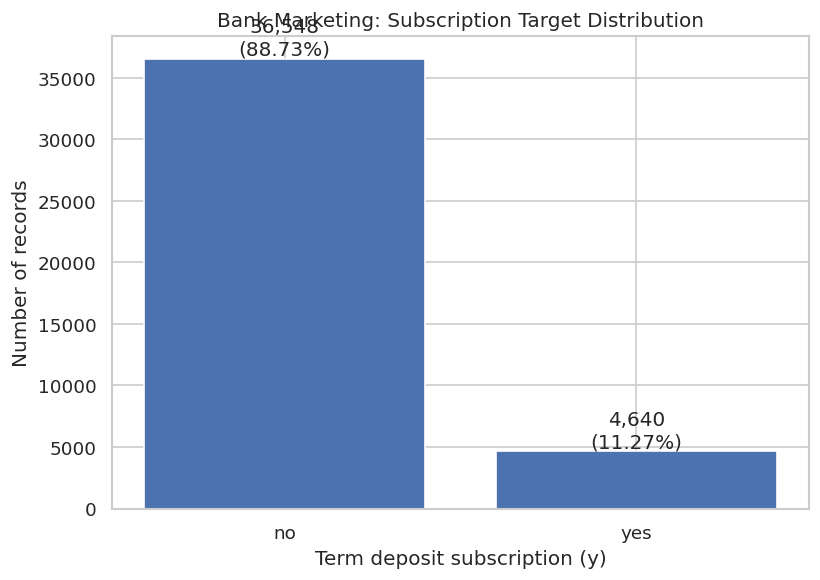

In [11]:
# Figure 1: Target distribution
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))
order = ["no", "yes"]
counts = df["y"].value_counts().reindex(order)
bars = ax.bar(counts.index, counts.values)
for bar, value in zip(bars, counts.values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height(),
            f"{value:,}\n({value/len(df)*100:.2f}%)", ha="center", va="bottom")
ax.set_title("Bank Marketing: Subscription Target Distribution")
ax.set_xlabel("Term deposit subscription (y)")
ax.set_ylabel("Number of records")
plt.tight_layout()
plt.savefig(FIG_DIR / "figure01_target_distribution.png", dpi=250, bbox_inches="tight")
plt.show()

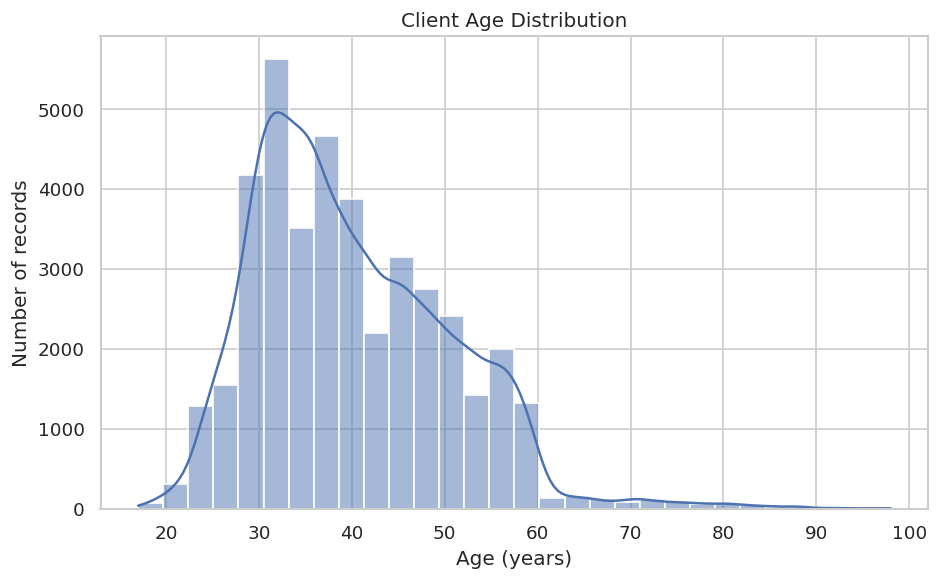

In [12]:
# Figure 2: Age distribution
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df["age"], bins=30, kde=True, ax=ax)
ax.set_title("Client Age Distribution")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of records")
plt.tight_layout()
plt.savefig(FIG_DIR / "figure02_age_distribution.png", dpi=250, bbox_inches="tight")
plt.show()

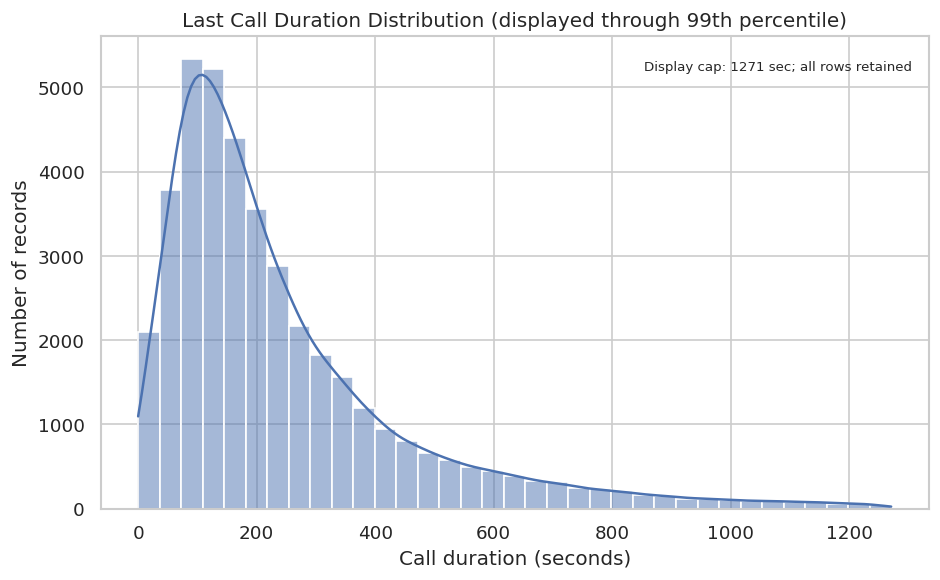

In [14]:
# Figure 3: Call duration distribution; plotting is limited to 99th percentile for readability.
# The underlying data are not removed or changed.
import matplotlib.pyplot as plt
import seaborn as sns

duration_q99 = df["duration"].quantile(0.99)
plot_duration = df.loc[df["duration"] <= duration_q99, "duration"]
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(plot_duration, bins=35, kde=True, ax=ax)
ax.set_title("Last Call Duration Distribution (displayed through 99th percentile)")
ax.set_xlabel("Call duration (seconds)")
ax.set_ylabel("Number of records")
ax.text(0.98, 0.95, f"Display cap: {duration_q99:.0f} sec; all rows retained",
        transform=ax.transAxes, ha="right", va="top", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "figure03_duration_distribution.png", dpi=250, bbox_inches="tight")
plt.show()

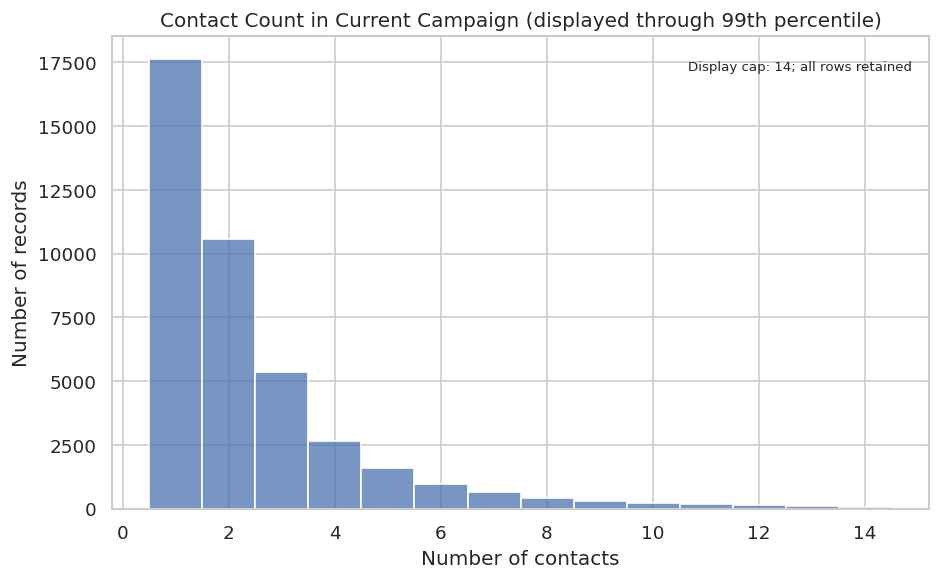

In [15]:
# Figure 4: Number of contacts during the current campaign (display capped at 99th percentile)
import matplotlib.pyplot as plt
import seaborn as sns

campaign_q99 = df["campaign"].quantile(0.99)
plot_campaign = df.loc[df["campaign"] <= campaign_q99, "campaign"]
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(plot_campaign, discrete=True, ax=ax)
ax.set_title("Contact Count in Current Campaign (displayed through 99th percentile)")
ax.set_xlabel("Number of contacts")
ax.set_ylabel("Number of records")
ax.text(0.98, 0.95, f"Display cap: {campaign_q99:.0f}; all rows retained",
        transform=ax.transAxes, ha="right", va="top", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "figure04_campaign_contacts.png", dpi=250, bbox_inches="tight")
plt.show()

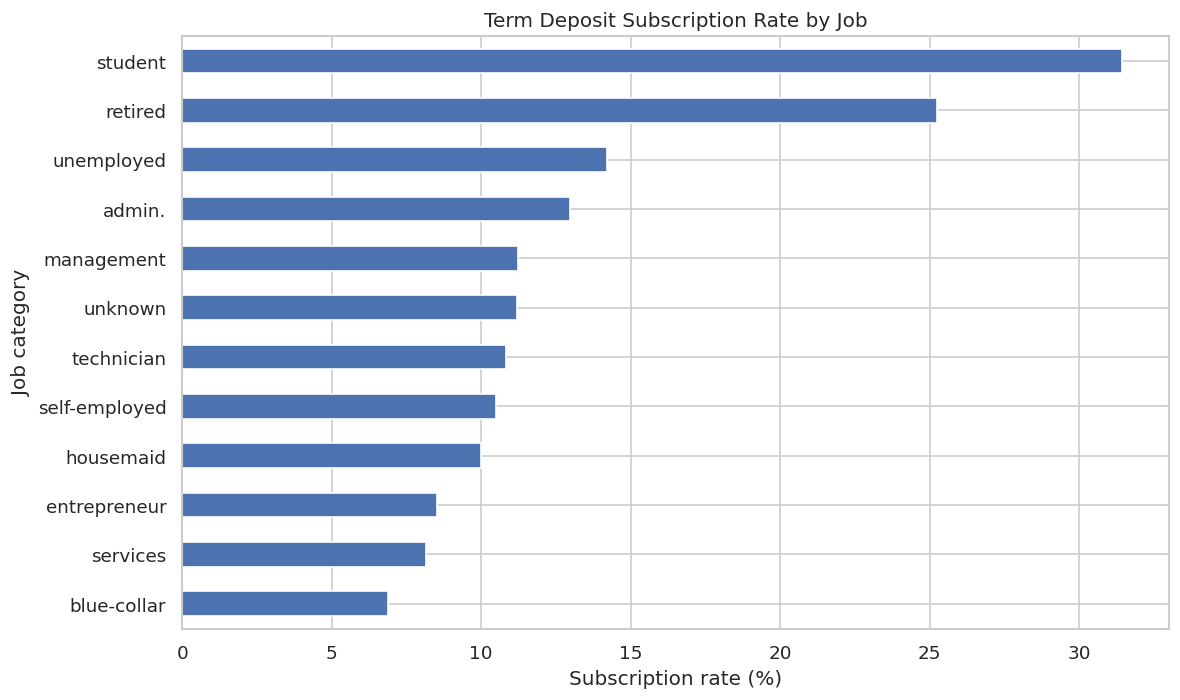

,subscription_rate_pct
job,
student,31.43
retired,25.23
unemployed,14.20
admin.,12.97
management,11.22
unknown,11.21
technician,10.83
self-employed,10.49
housemaid,10.00


In [16]:
# Figure 5: Subscription rate by job
import matplotlib.pyplot as plt

job_rate = (df.groupby("job", observed=False)["y"].apply(lambda s: (s == "yes").mean()*100)
            .sort_values(ascending=False))
fig, ax = plt.subplots(figsize=(10, 6))
job_rate.sort_values().plot(kind="barh", ax=ax)
ax.set_title("Term Deposit Subscription Rate by Job")
ax.set_xlabel("Subscription rate (%)")
ax.set_ylabel("Job category")
plt.tight_layout()
plt.savefig(FIG_DIR / "figure05_subscription_by_job.png", dpi=250, bbox_inches="tight")
plt.show()
display(job_rate.round(2).rename("subscription_rate_pct").to_frame())
job_rate.rename("subscription_rate_pct").to_csv(OUTPUT_DIR / "subscription_rate_by_job.csv")

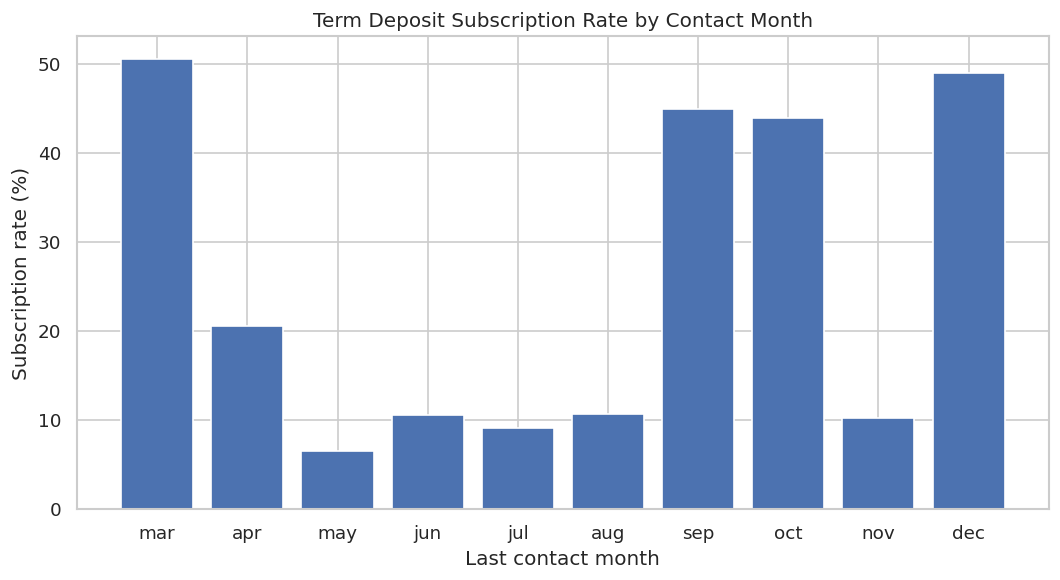

,subscription_rate_pct
month,
mar,50.55
apr,20.48
may,6.43
jun,10.51
jul,9.05
aug,10.60
sep,44.91
oct,43.87
nov,10.14


In [17]:
# Figure 6: Subscription rate by month
import matplotlib.pyplot as plt

month_order = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_rate = (df.groupby("month", observed=False)["y"].apply(lambda s: (s == "yes").mean()*100)
              .reindex(month_order).dropna())
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(month_rate.index, month_rate.values)
ax.set_title("Term Deposit Subscription Rate by Contact Month")
ax.set_xlabel("Last contact month")
ax.set_ylabel("Subscription rate (%)")
plt.tight_layout()
plt.savefig(FIG_DIR / "figure06_subscription_by_month.png", dpi=250, bbox_inches="tight")
plt.show()
display(month_rate.round(2).rename("subscription_rate_pct").to_frame())
month_rate.rename("subscription_rate_pct").to_csv(OUTPUT_DIR / "subscription_rate_by_month.csv")

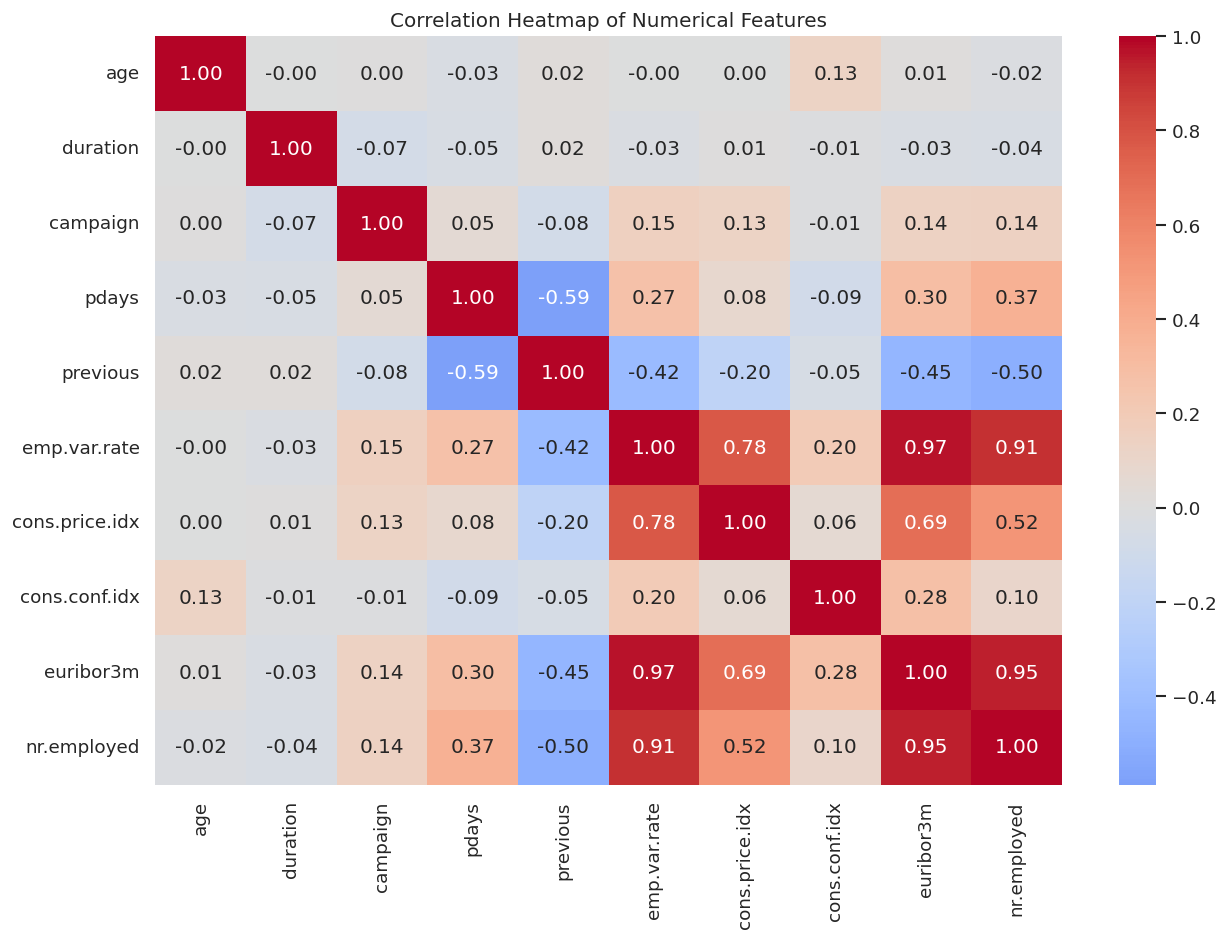

In [18]:
# Figure 7: Correlation heatmap for numeric variables
import matplotlib.pyplot as plt
import seaborn as sns

numeric_for_corr = [c for c in ["age", "duration", "campaign", "pdays", "previous",
                               "emp.var.rate", "cons.price.idx", "cons.conf.idx",
                               "euribor3m", "nr.employed"] if c in df.columns]
corr = df[numeric_for_corr].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.savefig(FIG_DIR / "figure07_correlation_heatmap.png", dpi=250, bbox_inches="tight")
plt.show()
corr.to_csv(OUTPUT_DIR / "numeric_correlation_matrix.csv")

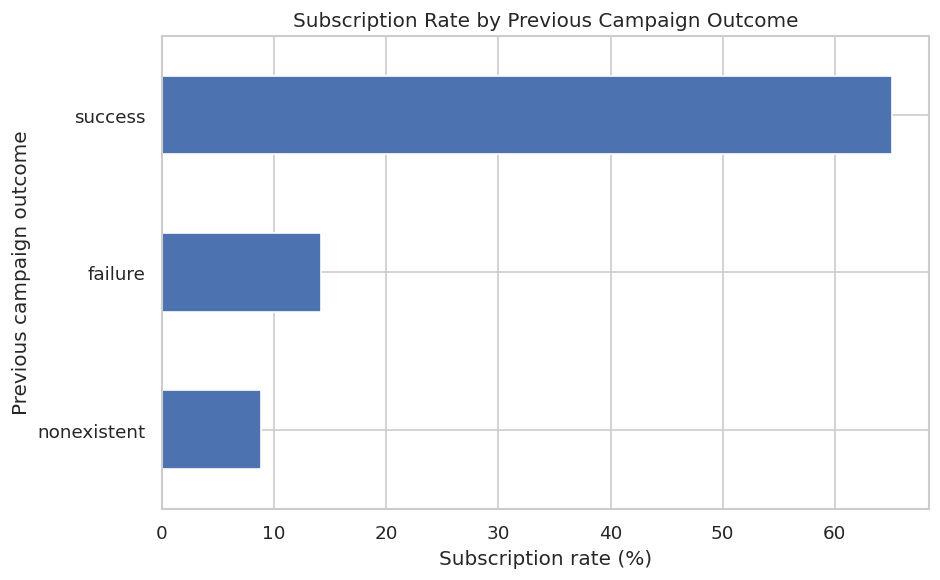

,subscription_rate_pct
poutcome,
success,65.11
failure,14.23
nonexistent,8.83


In [19]:
# Figure 8: Subscription rate by previous campaign outcome
import matplotlib.pyplot as plt

poutcome_rate = (df.groupby("poutcome", observed=False)["y"]
                 .apply(lambda s: (s == "yes").mean()*100)
                 .sort_values(ascending=False))
fig, ax = plt.subplots(figsize=(8, 5))
poutcome_rate.sort_values().plot(kind="barh", ax=ax)
ax.set_title("Subscription Rate by Previous Campaign Outcome")
ax.set_xlabel("Subscription rate (%)")
ax.set_ylabel("Previous campaign outcome")
plt.tight_layout()
plt.savefig(FIG_DIR / "figure08_subscription_by_previous_outcome.png", dpi=250, bbox_inches="tight")
plt.show()
display(poutcome_rate.round(2).rename("subscription_rate_pct").to_frame())
poutcome_rate.rename("subscription_rate_pct").to_csv(OUTPUT_DIR / "subscription_rate_by_previous_outcome.csv")

## 6. The seven stages of visualization

This project documents the seven-stage visualization workflow associated with Ben Fry: **Acquire, Parse, Filter, Mine, Represent, Refine, and Interact**.

1. **Acquire:** Download the Bank Marketing dataset from the UCI Machine Learning Repository.
2. **Parse:** Read the semicolon-separated CSV and inspect fields, data types, and target labels.
3. **Filter:** Check missing values, categorical `unknown` entries, duplicates, and potential outliers; retain observations unless there is evidence of invalidity.
4. **Mine:** Calculate descriptive statistics, subscription rates, and numerical correlations.
5. **Represent:** Use histograms, bar charts, and a correlation heatmap to represent distributions and relationships.
6. **Refine:** Add descriptive titles, readable axes, units, sensible tick labels, and captions.
7. **Interact:** Generate a Plotly chart with hover details in the next cell.

In [20]:
# Interactive visualization (stage 7): sample so the chart stays responsive.
import plotly.express as px

interactive_df = df.sample(n=min(2500, len(df)), random_state=SEED)
fig_interactive = px.scatter(
    interactive_df,
    x="age", y="campaign", color="y",
    hover_data=["job", "education", "month", "poutcome"],
    title="Interactive Exploration: Age vs Campaign Contacts",
    labels={"age": "Age (years)", "campaign": "Contacts in current campaign", "y": "Subscribed?"}
)
fig_interactive.write_html(str(OUTPUT_DIR / "interactive_age_vs_campaign.html"), include_plotlyjs="cdn")
fig_interactive.show()

## 7. Prepare data for Deep Learning

The target `y` is encoded as 1 for `yes` and 0 for `no`. A stratified split separates training (70%), validation (15%), and test (15%) data. Numerical columns are median-imputed and standardized; categorical columns are imputed with the most frequent category and one-hot encoded.

**Leakage prevention:** `duration` is excluded from the predictive model because it is known only after the current call. It remains available for EDA. Preprocessing is fitted only on the training set and then applied unchanged to validation and test partitions.

In [21]:
# Features and target. Exclude duration to avoid post-call target leakage.
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

TARGET = "y"
LEAKAGE_FEATURE = "duration"
X = df.drop(columns=[TARGET, LEAKAGE_FEATURE]).copy()
y = df[TARGET].map({"no": 0, "yes": 1}).astype(int)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

try:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:  # compatibility with older scikit-learn
    onehot = OneHotEncoder(handle_unknown="ignore", sparse=False)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", onehot)
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

X_train_processed = np.asarray(preprocessor.fit_transform(X_train), dtype=np.float32)
X_val_processed = np.asarray(preprocessor.transform(X_val), dtype=np.float32)
X_test_processed = np.asarray(preprocessor.transform(X_test), dtype=np.float32)
y_train_np = y_train.to_numpy(dtype=np.float32)
y_val_np = y_val.to_numpy(dtype=np.float32)
y_test_np = y_test.to_numpy(dtype=np.int32)

print("Train:", X_train_processed.shape, "Validation:", X_val_processed.shape,
      "Test:", X_test_processed.shape)
print("Target subscription rates (%) - train/validation/test:",
      round(y_train.mean()*100, 2), round(y_val.mean()*100, 2), round(y_test.mean()*100, 2))
print("NaN values in processed data:",
      int(np.isnan(X_train_processed).sum() + np.isnan(X_val_processed).sum() + np.isnan(X_test_processed).sum()))

classes = np.array([0, 1])
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train.to_numpy())
class_weight = {int(c): float(w) for c, w in zip(classes, weights)}
print("Training class weights:", class_weight)

Train: (28831, 62) Validation: (6178, 62) Test: (6179, 62)
Target subscription rates (%) - train/validation/test: 11.27 11.27 11.26
NaN values in processed data: 0
Training class weights: {0: 0.5634796544580385, 1: 4.438269704433497}


## 8. Build and compare two MLP Deep Learning configurations

Both configurations use binary cross-entropy, Adam, a sigmoid output, class weights to account for target imbalance, and early stopping on validation AUC. The validation data is used to select the configuration; the test set is held back for final reporting.

In [22]:
def build_mlp(input_dim, hidden_units=(64, 32), dropout_rate=0.25, learning_rate=0.001):
    model = keras.Sequential(name="campaignpulse_mlp")
    model.add(layers.Input(shape=(input_dim,)))
    for units in hidden_units:
        model.add(layers.Dense(units, activation="relu"))
        model.add(layers.Dropout(dropout_rate))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc")
        ]
    )
    return model

configs = [
    {"name": "MLP_A", "hidden_units": (64, 32), "dropout": 0.25, "learning_rate": 0.001},
    {"name": "MLP_B", "hidden_units": (32, 16), "dropout": 0.30, "learning_rate": 0.0005},
]
models, histories, comparison_rows = {}, {}, []

for cfg in configs:
    print("\nTraining", cfg["name"], "configuration:", cfg)
    model = build_mlp(
        X_train_processed.shape[1],
        hidden_units=cfg["hidden_units"],
        dropout_rate=cfg["dropout"],
        learning_rate=cfg["learning_rate"]
    )
    early_stop = EarlyStopping(
        monitor="val_auc", mode="max", patience=4,
        restore_best_weights=True, verbose=1
    )
    history = model.fit(
        X_train_processed, y_train_np,
        validation_data=(X_val_processed, y_val_np),
        epochs=30, batch_size=256,
        class_weight=class_weight,
        callbacks=[early_stop], verbose=1
    )
    models[cfg["name"]] = model
    histories[cfg["name"]] = history
    best_idx = int(np.argmax(history.history["val_auc"]))
    comparison_rows.append({
        "model": cfg["name"],
        "hidden_units": str(cfg["hidden_units"]),
        "dropout": cfg["dropout"],
        "learning_rate": cfg["learning_rate"],
        "best_epoch_by_val_auc": best_idx + 1,
        "best_val_auc": float(history.history["val_auc"][best_idx]),
        "val_loss_at_best_auc_epoch": float(history.history["val_loss"][best_idx])
    })

model_comparison = pd.DataFrame(comparison_rows).sort_values("best_val_auc", ascending=False)
display(model_comparison.round(4))
model_comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
best_model_name = str(model_comparison.iloc[0]["model"])
best_model = models[best_model_name]
best_history = histories[best_model_name]
best_config = next(c for c in configs if c["name"] == best_model_name)
print("Selected model based on validation AUC:", best_model_name)


Training MLP_A configuration: {'name': 'MLP_A', 'hidden_units': (64, 32), 'dropout': 0.25, 'learning_rate': 0.001}
Epoch 1/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7355 - auc: 0.7039 - loss: 0.6258 - precision: 0.2299 - recall: 0.5739 - val_accuracy: 0.7863 - val_auc: 0.7848 - val_loss: 0.5460 - val_precision: 0.3020 - val_recall: 0.6839
Epoch 2/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7898 - auc: 0.7728 - loss: 0.5628 - precision: 0.2986 - recall: 0.6416 - val_accuracy: 0.8276 - val_auc: 0.7931 - val_loss: 0.5209 - val_precision: 0.3535 - val_recall: 0.6394
Epoch 3/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8113 - auc: 0.7783 - loss: 0.5548 - precision: 0.3259 - recall: 0.6321 - val_accuracy: 0.8388 - val_auc: 0.7955 - val_loss: 0.5119 - val_precision: 0.3718 - val_recall: 0.6250
Epoch 4/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8181 - auc: 0.7833 - loss: 0.5504 - precision: 0.3356 - recall: 0.6275 - val_accuracy: 0.835

,model,hidden_units,dropout,learning_rate,best_epoch_by_val_auc,best_val_auc,val_loss_at_best_auc_epoch
0,MLP_A,"(64, 32)",0.25,0.0010,14,0.8041,0.4942
1,MLP_B,"(32, 16)",0.30,0.0005,30,0.8037,0.5014


Selected model based on validation AUC: MLP_A


## 9. Training result visualizations

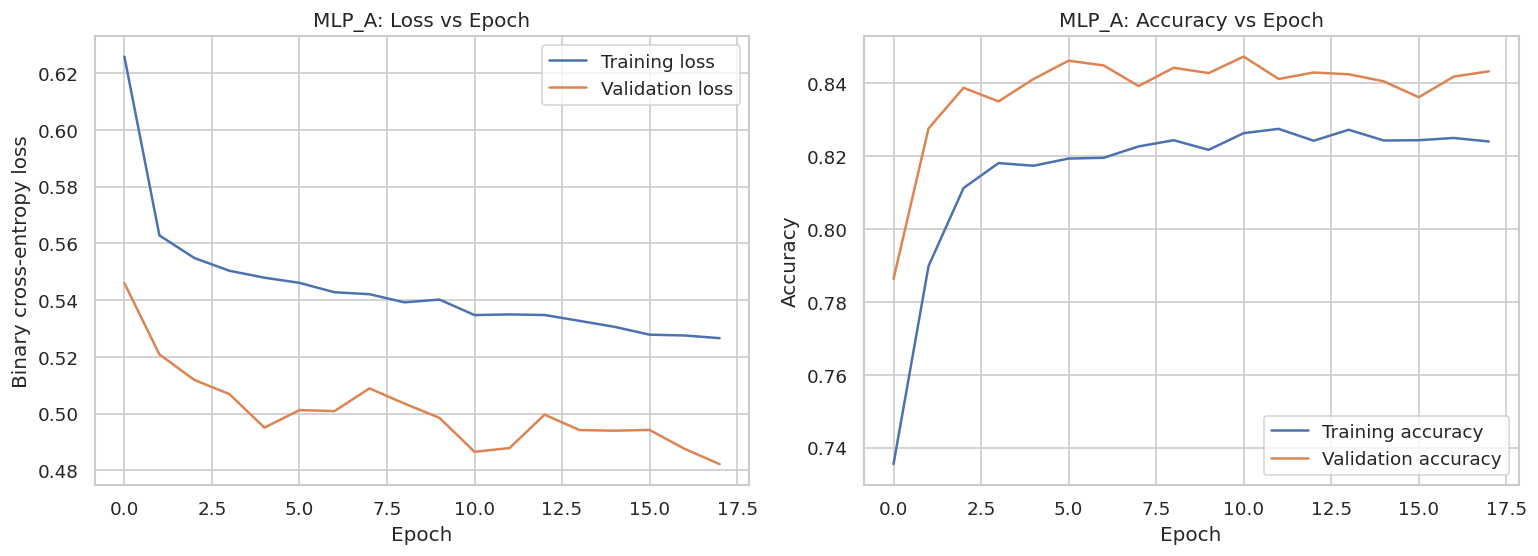

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(best_history.history["loss"], label="Training loss")
axes[0].plot(best_history.history["val_loss"], label="Validation loss")
axes[0].set_title(f"{best_model_name}: Loss vs Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy loss")
axes[0].legend()
axes[1].plot(best_history.history["accuracy"], label="Training accuracy")
axes[1].plot(best_history.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title(f"{best_model_name}: Accuracy vs Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "figure09_training_curves.png", dpi=250, bbox_inches="tight")
plt.show()

## 10. Final test-set evaluation

The held-out test set is used only for the final evaluation after model selection. Results can vary slightly with TensorFlow and hardware versions; the values generated in your run should be used in the report.

Selected model: MLP_A


,Metric,Score
0,Accuracy,0.8437
1,Precision,0.3850
2,Recall,0.6494
3,F1-score,0.4834
4,ROC-AUC,0.8009



Classification report:
                 precision    recall  f1-score   support

No subscription       0.95      0.87      0.91      5483
     Subscribed       0.39      0.65      0.48       696

       accuracy                           0.84      6179
      macro avg       0.67      0.76      0.70      6179
   weighted avg       0.89      0.84      0.86      6179



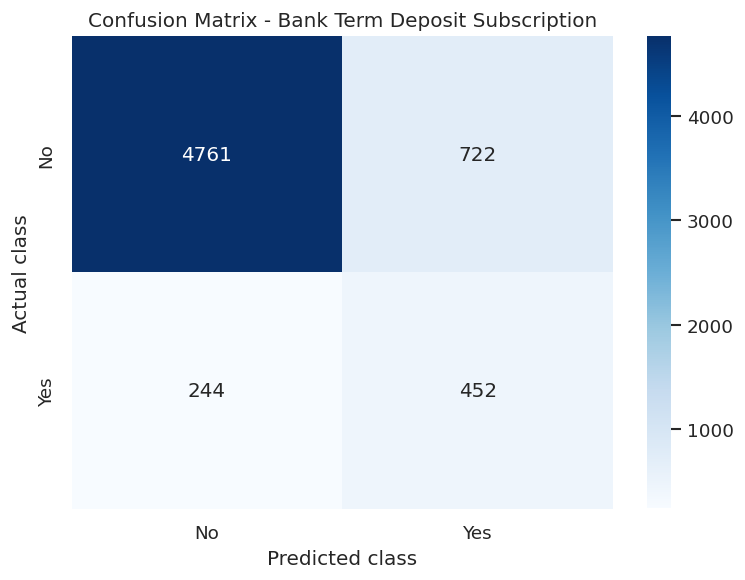

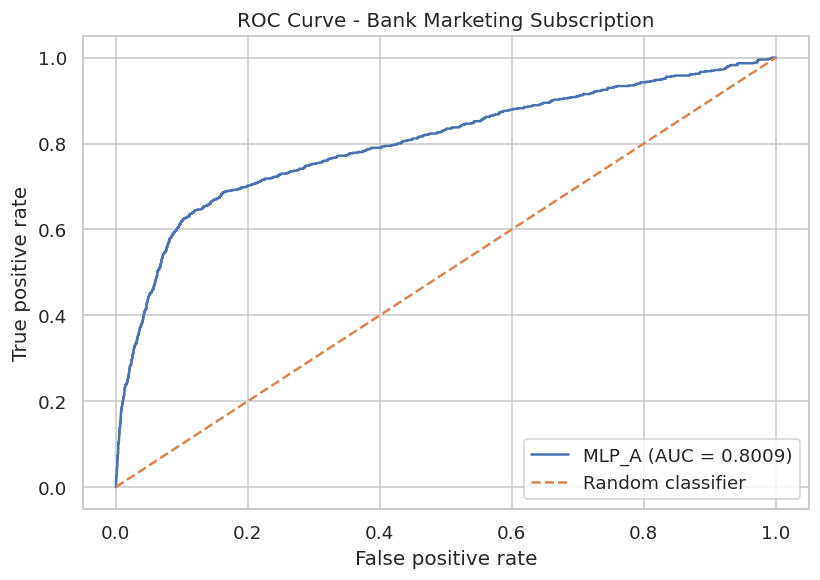

In [24]:
# Final test evaluation
y_test_prob = best_model.predict(X_test_processed, verbose=0).ravel()
y_test_pred = (y_test_prob >= 0.50).astype(int)

metrics = {
    "Accuracy": accuracy_score(y_test_np, y_test_pred),
    "Precision": precision_score(y_test_np, y_test_pred, zero_division=0),
    "Recall": recall_score(y_test_np, y_test_pred, zero_division=0),
    "F1-score": f1_score(y_test_np, y_test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test_np, y_test_prob)
}
metrics_df = pd.DataFrame([{"Metric": k, "Score": float(v)} for k, v in metrics.items()])
print("Selected model:", best_model_name)
display(metrics_df.round(4))
print("\nClassification report:")
print(classification_report(y_test_np, y_test_pred,
                            labels=[0, 1], target_names=["No subscription", "Subscribed"],
                            zero_division=0))
metrics_df.to_csv(OUTPUT_DIR / "test_evaluation_metrics.csv", index=False)

# Confusion matrix
cm = confusion_matrix(y_test_np, y_test_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No", "Yes"], yticklabels=["No", "Yes"], ax=ax)
ax.set_title("Confusion Matrix - Bank Term Deposit Subscription")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
plt.tight_layout()
plt.savefig(FIG_DIR / "figure10_confusion_matrix.png", dpi=250, bbox_inches="tight")
plt.show()

# ROC curve
fpr, tpr, _ = roc_curve(y_test_np, y_test_prob)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(fpr, tpr, label=f"{best_model_name} (AUC = {metrics["ROC-AUC"]:.4f})")
ax.plot([0, 1], [0, 1], "--", label="Random classifier")
ax.set_title("ROC Curve - Bank Marketing Subscription")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "figure11_roc_curve.png", dpi=250, bbox_inches="tight")
plt.show()

## 11. Feature importance using permutation importance

Permutation importance shuffles one original input feature at a time and measures the reduction in validation ROC-AUC. It measures model reliance, not causal effect. Two repeats are used to keep runtime manageable.

Baseline validation ROC-AUC: 0.8040


,Feature,Importance
18,nr.employed,0.0311
8,month,0.0281
14,emp.var.rate,0.0275
7,contact,0.0105
10,campaign,0.0073
11,pdays,0.0073
9,day_of_week,0.0055
17,euribor3m,0.0049
4,default,0.0029
15,cons.price.idx,0.0026


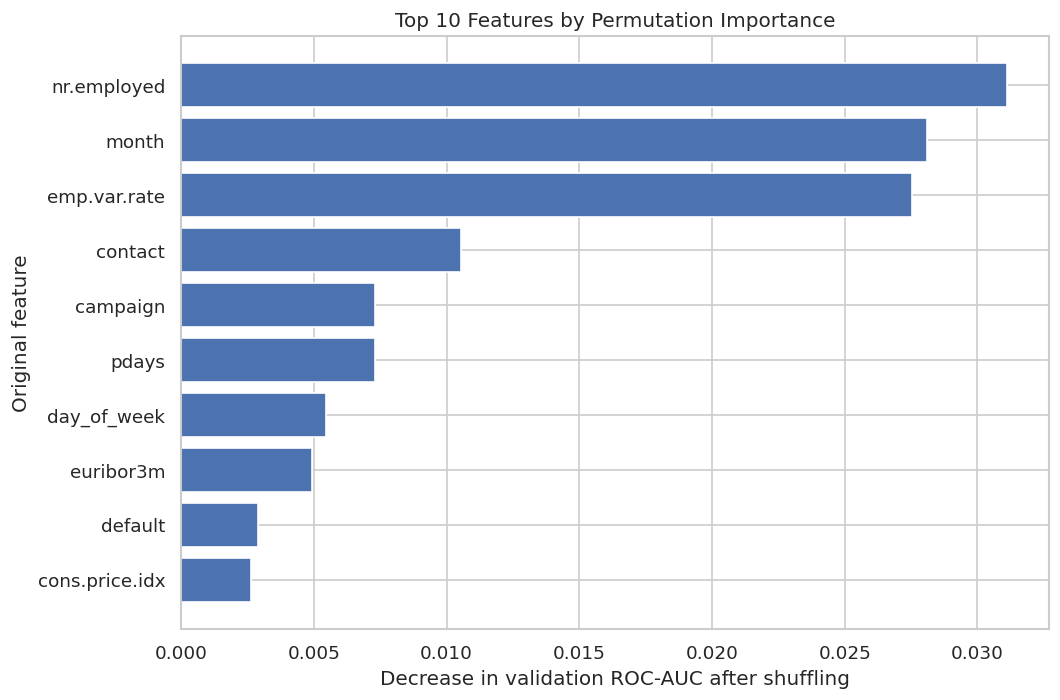

In [25]:
# Baseline validation AUC on transformed validation features
val_prob_baseline = best_model.predict(X_val_processed, verbose=0).ravel()
val_auc_baseline = roc_auc_score(y_val, val_prob_baseline)
rng = np.random.default_rng(SEED)
importance_rows = []

for feature in X_val.columns:
    drops = []
    for _ in range(2):
        X_perm = X_val.copy()
        X_perm[feature] = rng.permutation(X_perm[feature].to_numpy())
        X_perm_proc = np.asarray(preprocessor.transform(X_perm), dtype=np.float32)
        perm_prob = best_model.predict(X_perm_proc, verbose=0).ravel()
        drops.append(val_auc_baseline - roc_auc_score(y_val, perm_prob))
    importance_rows.append({"Feature": feature, "Importance": float(np.mean(drops))})

importance_df = pd.DataFrame(importance_rows).sort_values("Importance", ascending=False)
importance_df.to_csv(OUTPUT_DIR / "feature_importance.csv", index=False)
print(f"Baseline validation ROC-AUC: {val_auc_baseline:.4f}")
display(importance_df.round(4))

top_imp = importance_df.head(10).sort_values("Importance", ascending=True)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_imp["Feature"], top_imp["Importance"])
ax.axvline(0, linestyle="--", linewidth=1, color="gray")
ax.set_title("Top 10 Features by Permutation Importance")
ax.set_xlabel("Decrease in validation ROC-AUC after shuffling")
ax.set_ylabel("Original feature")
plt.tight_layout()
plt.savefig(FIG_DIR / "figure12_permutation_importance.png", dpi=250, bbox_inches="tight")
plt.show()

## 12. Generate a report DOCX with your actual run results

After all prior cells have run, this cell builds `report/CampaignPulse_Project_Report.docx`. It fills result tables, summary statistics, interpretations, and saved figures from the actual notebook outputs. Replace the student details in the configuration cell before generating the final report. Review the document and export it to PDF using Microsoft Word or Google Docs before submitting.

In [26]:
# Generate a formatted report containing values and figures from this actual run.
from docx.enum.section import WD_SECTION
from docx.enum.style import WD_STYLE_TYPE

report_path = REPORT_DIR / "CampaignPulse_Project_Report.docx"
report = Document()
section = report.sections[0]
section.top_margin = Inches(0.7)
section.bottom_margin = Inches(0.7)
section.left_margin = Inches(0.8)
section.right_margin = Inches(0.8)

styles = report.styles
styles["Normal"].font.name = "Arial"
styles["Normal"].font.size = Pt(10)
styles["Normal"].paragraph_format.space_after = Pt(5)
for style_name, size, color in [("Title", 24, "17365D"), ("Heading 1", 16, "17365D"), ("Heading 2", 12, "2F5597")]:
    st = styles[style_name]
    st.font.name = "Arial"
    st.font.size = Pt(size)
    st.font.bold = True
    st.font.color.rgb = RGBColor.from_string(color)

def add_center(text, size=12, bold=False):
    p = report.add_paragraph()
    p.alignment = WD_ALIGN_PARAGRAPH.CENTER
    r = p.add_run(text)
    r.bold = bold
    r.font.size = Pt(size)
    r.font.name = "Arial"
    return p

def add_bullet(text):
    report.add_paragraph(text, style="List Bullet")

def add_table(headers, rows):
    table = report.add_table(rows=1, cols=len(headers))
    table.style = "Light Shading Accent 1"
    table.alignment = WD_TABLE_ALIGNMENT.CENTER
    for i, h in enumerate(headers):
        table.rows[0].cells[i].text = str(h)
        table.rows[0].cells[i].vertical_alignment = WD_CELL_VERTICAL_ALIGNMENT.CENTER
    for row in rows:
        cells = table.add_row().cells
        for i, value in enumerate(row):
            cells[i].text = str(value)
            cells[i].vertical_alignment = WD_CELL_VERTICAL_ALIGNMENT.CENTER
    return table

def add_figure(filename, caption, width=6.1):
    path = FIG_DIR / filename
    if path.exists():
        p = report.add_paragraph()
        p.alignment = WD_ALIGN_PARAGRAPH.CENTER
        p.add_run().add_picture(str(path), width=Inches(width))
        cp = report.add_paragraph(caption)
        cp.alignment = WD_ALIGN_PARAGRAPH.CENTER
        if cp.runs:
            cp.runs[0].italic = True
            cp.runs[0].font.size = Pt(9)

def add_page_number(section):
    footer = section.footer.paragraphs[0]
    footer.alignment = WD_ALIGN_PARAGRAPH.CENTER
    footer.add_run("CampaignPulse: Bank Campaign Response Analysis")

add_center(INSTITUTE, 14, True)
add_center(DEPARTMENT, 12, True)
report.add_paragraph("\n")
add_center("EXPLORATORY DATA ANALYSIS AND VISUALIZATION", 17, True)
add_center("CampaignPulse: Exploring Customer Response to Bank Term-Deposit Campaigns with EDA and Deep Learning", 20, True)
report.add_paragraph("\n")
add_center(f"Submitted by: {STUDENT_NAME}", 12, True)
add_center(f"Roll Number: {ROLL_NUMBER}", 12)
add_center("Course: Exploratory Data Analysis and Visualization", 11)
add_center(f"Submission Date: {SUBMISSION_DATE}", 11)
report.add_page_break()

report.add_heading("Abstract", level=1)
yes_pct = float((df["y"] == "yes").mean() * 100)
no_pct = float((df["y"] == "no").mean() * 100)
report.add_paragraph(
    f"This project applies exploratory data analysis, statistical analysis, visualization, and Deep Learning to the UCI Bank Marketing dataset. "
    f"The selected bank-additional-full dataset contains {len(df):,} campaign records and {df.shape[1]-1} input attributes with a binary target indicating whether a client subscribed to a term deposit. "
    f"Preprocessing included type inspection, missing-value and duplicate checks, categorical handling, one-hot encoding, and numerical standardization. "
    f"Eight EDA charts explore the target distribution, client age, call and campaign distributions, subscription rate by job and month, numerical correlations, and previous campaign outcomes. "
    f"Two MLP configurations were compared using validation ROC-AUC, and the selected model was evaluated on a held-out test set using accuracy, precision, recall, F1-score, and ROC-AUC. "
    f"The observed subscription rate was {yes_pct:.2f}%. Final model scores and the leading permutation-importance features are reported in this document from the executed notebook. "
    f"Call duration was excluded from model predictors because it is only known after the current call."
)

report.add_heading("1. Introduction", level=1)
report.add_paragraph(
    "Marketing campaigns allow banks to contact potential customers about financial products. Understanding which customer and campaign attributes are associated with term-deposit subscriptions can help describe campaign patterns and support further analysis. "
    "This project explores historical campaign data and develops an MLP binary classifier. The results describe association and predictive performance; they do not establish causal relationships or guarantee outcomes for future campaigns."
)
report.add_heading("1.1 Objectives", level=2)
for item in [
    "Inspect the data structure and identify important numerical and categorical attributes.",
    "Assess missing values, unknown-category labels, duplicates, and potential outliers.",
    "Create more than five meaningful visualizations and explain their insights.",
    "Build and compare at least two MLP configurations with validation-based selection.",
    "Evaluate the selected model using a held-out test set and visualize its performance.",
    "Use permutation importance to investigate which features the model relies on most."
]: add_bullet(item)

report.add_heading("2. Dataset Description", level=1)
report.add_paragraph(
    "The project uses `bank-additional-full.csv` from the UCI Bank Marketing dataset. The records describe a Portuguese banking institution's direct marketing campaigns conducted through phone calls. The target column `y` indicates term-deposit subscription (`yes` or `no`). The selected variant has 41,188 records and 21 columns in the standard source version."
)
add_table(["Item", "Description"], [
    ["Dataset source", "UCI Machine Learning Repository - Bank Marketing"],
    ["File variant", "bank-additional-full.csv (semicolon-separated CSV)"],
    ["Rows in executed dataset", f"{len(df):,}"],
    ["Columns", str(df.shape[1])],
    ["Target variable", "y (yes/no subscription)"],
    ["Predictor fields in modelling", str(X.shape[1]) + " (duration excluded to avoid leakage)"],
    ["Source URL", "https://archive.ics.uci.edu/dataset/222/bank+marketing"]
])
report.add_heading("3. Data Understanding and Preprocessing", level=1)
report.add_paragraph(
    f"The loaded dataset contains {len(df):,} rows and {df.shape[1]} columns. The executed data-quality check found {int(df.isna().sum().sum())} conventional missing cells. "
    f"The check counted {int(df.duplicated().sum())} exact duplicate rows; duplicates were reported rather than automatically removed because no unique client identifier is available to determine whether matching profiles are data errors. "
    "Categorical values labelled `unknown` were retained as a valid category in the original coding. Numeric outlier screening used the interquartile-range rule for selected fields; possible outliers were not removed automatically because extreme values can be real campaign observations. "
    "Numerical predictors were median-imputed and standardized. Categorical predictors were imputed with the most-frequent category and one-hot encoded. The preprocessing pipeline was fitted only on training data to avoid leakage."
)
report.add_heading("3.1 Train, Validation, and Test Split", level=2)
add_table(["Partition", "Records", "Purpose"], [
    ["Training", f"{len(X_train):,}", "Fit model parameters"],
    ["Validation", f"{len(X_val):,}", "Compare configurations and select a model"],
    ["Testing", f"{len(X_test):,}", "Final independent evaluation"]
])
report.add_paragraph(
    f"The split was stratified by the target with proportions of 70% training, 15% validation and 15% testing. Subscription rate in the complete dataset was {yes_pct:.2f}%, while the non-subscription rate was {no_pct:.2f}%. Class weighting was used during training to address this imbalance."
)

report.add_heading("4. Exploratory Data Analysis and Visualizations", level=1)
report.add_paragraph("Each visualization was selected to answer a specific exploratory question. Distribution charts describe one variable; grouped rates compare subscription outcomes across categories; the heatmap explores numerical association.")

rate_job = (df.groupby("job", observed=False)["y"].apply(lambda s: (s == "yes").mean()*100).sort_values(ascending=False))
rate_month = (df.groupby("month", observed=False)["y"].apply(lambda s: (s == "yes").mean()*100).reindex(["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]).dropna())
rate_outcome = df.groupby("poutcome", observed=False)["y"].apply(lambda s: (s == "yes").mean()*100).sort_values(ascending=False)
mean_age = float(df["age"].mean())
median_age = float(df["age"].median())
mean_dur = float(df["duration"].mean())
mean_campaign = float(df["campaign"].mean())

figure_texts = [
    ("figure01_target_distribution.png", "Figure 1. Subscription target distribution.", f"The overall observed subscription rate was {yes_pct:.2f}% and the non-subscription rate was {no_pct:.2f}%. This shows the target is imbalanced, so accuracy alone is not an adequate evaluation measure."),
    ("figure02_age_distribution.png", "Figure 2. Distribution of client age.", f"Mean client age was {mean_age:.2f} years and median age was {median_age:.2f} years. The histogram provides the shape and spread of the age distribution."),
    ("figure03_duration_distribution.png", "Figure 3. Last-call duration distribution (display shown through the 99th percentile).", f"Mean call duration was {mean_dur:.2f} seconds. The plot limits its displayed range for readability, while all source rows are retained. Duration is used for EDA but excluded from the model to avoid post-call leakage."),
    ("figure04_campaign_contacts.png", "Figure 4. Number of contacts during the current campaign.", f"The average number of contacts during the current campaign was {mean_campaign:.2f}. The chart displays values through the 99th percentile to make the central distribution easier to inspect; it does not delete observations."),
    ("figure05_subscription_by_job.png", "Figure 5. Subscription rate by job category.", f"The highest observed job-category subscription rate was for '{rate_job.index[0]}' ({rate_job.iloc[0]:.2f}%). This is a descriptive association; category sizes and other factors should also be considered."),
    ("figure06_subscription_by_month.png", "Figure 6. Subscription rate by contact month.", f"The highest observed month-specific subscription rate was in '{rate_month.idxmax()}' ({rate_month.max():.2f}%). Differences may reflect campaign design and historical context and should not be interpreted as causal effects."),
    ("figure07_correlation_heatmap.png", "Figure 7. Correlation heatmap for numeric attributes.", "The heatmap shows pairwise linear correlations between numerical attributes. Correlation indicates association rather than causation, and some variables may be related because they measure similar economic or campaign conditions."),
    ("figure08_subscription_by_previous_outcome.png", "Figure 8. Subscription rate by previous campaign outcome.", f"The highest observed rate by previous campaign outcome was for '{rate_outcome.index[0]}' ({rate_outcome.iloc[0]:.2f}%). This pattern is useful for describing campaign history, but does not guarantee the same rate in future campaigns.")
]
for fname, caption, interpretation in figure_texts:
    add_figure(fname, caption, width=6.1)
    report.add_paragraph("Interpretation: " + interpretation)

report.add_heading("5. Seven Stages of Visualization", level=1)
add_table(["Stage", "Project implementation"], [
    ["Acquire", "Download the data from the UCI Machine Learning Repository."],
    ["Parse", "Read the semicolon-separated CSV and inspect column types."],
    ["Filter", "Inspect missing values, unknown categories, duplicates, and potential outliers."],
    ["Mine", "Compute descriptive statistics, grouped subscription rates, and correlations."],
    ["Represent", "Create histograms, category-rate charts and a correlation heatmap."],
    ["Refine", "Add clear chart titles, axes, scales, legends and captions."],
    ["Interact", "Create a Plotly chart with hover information and save it as HTML."]
])
report.add_paragraph("The interactive chart is saved as `outputs/interactive_age_vs_campaign.html` within the generated project output directory.")

report.add_heading("6. Deep Learning Model", level=1)
report.add_paragraph(
    f"A feed-forward Multilayer Perceptron (MLP) was implemented using TensorFlow/Keras. The selected configuration was {best_model_name}, with hidden layers {best_config['hidden_units']}, ReLU activations, dropout {best_config['dropout']}, Adam optimizer, learning rate {best_config['learning_rate']}, binary cross-entropy loss, batch size 256, and a maximum of 30 epochs. Early stopping monitored validation ROC-AUC and restored the best weights. Class weights were used to mitigate target imbalance."
)
report.add_paragraph(
    "The UCI dataset documentation warns that `duration` is only known after a call and is highly related to the outcome. Therefore, duration was used for exploratory analysis but excluded from the predictive features, making the model's intended use closer to a pre-contact prediction setting."
)
report.add_heading("6.1 Hyperparameter Comparison", level=2)
comparison_table = []
for _, row in model_comparison.iterrows():
    comparison_table.append([row["model"], row["hidden_units"], row["dropout"], row["learning_rate"], row["best_epoch_by_val_auc"], f"{row['best_val_auc']:.4f}"])
add_table(["Model", "Hidden units", "Dropout", "Learning rate", "Best epoch", "Best validation AUC"], comparison_table)
report.add_paragraph(f"{best_model_name} was selected because it achieved the higher validation ROC-AUC among the configurations compared. The test set was not used for this selection.")
add_figure("figure09_training_curves.png", "Figure 9. Training and validation loss and accuracy for the selected MLP.", width=6.3)
report.add_paragraph("The training curves show how the model learned across epochs. Divergence between training and validation curves can indicate overfitting; the early-stopping strategy helps limit unnecessary training.")

report.add_heading("7. Model Evaluation and Results", level=1)
metric_rows = [[name, f"{value:.4f}", f"{value*100:.2f}%" if name != "ROC-AUC" else f"{value:.4f}"] for name, value in metrics.items()]
add_table(["Metric", "Score", "Percentage where applicable"], metric_rows)
report.add_paragraph(
    f"On the held-out test set, the model obtained accuracy {metrics['Accuracy']:.4f}, precision {metrics['Precision']:.4f}, recall {metrics['Recall']:.4f}, F1-score {metrics['F1-score']:.4f}, and ROC-AUC {metrics['ROC-AUC']:.4f}. Precision and recall refer to the positive 'yes' subscription class at a threshold of 0.50."
)
add_figure("figure10_confusion_matrix.png", "Figure 10. Confusion matrix on the test set.", width=5.8)
report.add_paragraph(f"The confusion matrix contains {int(cm[0,0])} true negatives, {int(cm[0,1])} false positives, {int(cm[1,0])} false negatives and {int(cm[1,1])} true positives (class order: no, yes). False negatives are potential subscribers missed by the classifier, while false positives are clients predicted to subscribe who did not subscribe.")
add_figure("figure11_roc_curve.png", "Figure 11. ROC curve with test ROC-AUC.", width=5.8)
report.add_paragraph("ROC-AUC measures the ranking ability of the classifier across score thresholds. The ROC curve should be interpreted together with precision and recall, especially because the target distribution is imbalanced.")

report.add_heading("8. Feature Importance", level=1)
add_figure("figure12_permutation_importance.png", "Figure 12. Top features by permutation importance on validation data.", width=6.1)
report.add_paragraph(f"Permutation importance was calculated on the validation data. The top three features in this run were: " + ", ".join([f"{r['Feature']} ({r['Importance']:.4f})" for _, r in importance_df.head(3).iterrows()]) + ". Positive values mean shuffling the feature reduced validation ROC-AUC. These results measure model reliance, not cause-and-effect relationships. Correlated features can share predictive information.")

report.add_heading("9. Conclusion", level=1)
report.add_paragraph(
    f"This project performed data understanding, cleaning checks, statistical analysis, EDA visualizations and MLP-based prediction using the UCI Bank Marketing dataset. The observed subscription rate was {yes_pct:.2f}%. The selected model ({best_model_name}) achieved {metrics['Accuracy']*100:.2f}% test accuracy and a test ROC-AUC of {metrics['ROC-AUC']:.4f}; its recall for the subscribed class was {metrics['Recall']*100:.2f}%. These metrics should be considered together because the classes are imbalanced. The main insights include category-level differences in subscription rates and the predictive contributions identified by permutation importance. The analysis is observational, relates to a historical campaign dataset, and should not be treated as a causal or guaranteed forecast."
)

report.add_heading("10. Future Scope", level=1)
for item in [
    "Tune the decision threshold using validation data to select an appropriate precision-recall trade-off.",
    "Compare the MLP with logistic regression, gradient boosting, and other baseline classifiers.",
    "Use repeated stratified cross-validation and report variability across folds.",
    "Investigate alternative class-imbalance strategies and calibration of predicted probabilities.",
    "Validate on newer campaign data before applying the analysis to current marketing decisions.",
    "Explore feature interactions and assess whether patterns remain stable across time periods and customer groups."
]: add_bullet(item)

report.add_heading("11. Literature Review", level=1)
report.add_paragraph("The UCI Bank Marketing repository documents the data source, attributes, task definition and an important limitation of the duration variable. Moro, Rita and Cortez (2014) studied data-driven prediction of telemarketing success, providing the research context for this dataset. Fry (2008) describes the staged visualization workflow used to organize acquisition through interaction. The Keras documentation describes the Sequential API used to stack dense neural-network layers. The scikit-learn documentation describes preprocessing and permutation importance concepts used in this project.")

report.add_heading("12. References", level=1)
references = [
    "Moro, S., Rita, P., & Cortez, P. (2014). Bank Marketing [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306",
    "Moro, S., Cortez, P., & Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. Decision Support Systems, 62, 22-31. https://doi.org/10.1016/j.dss.2014.03.001",
    "Fry, B. (2008). Visualizing Data: Exploring and Explaining Data with the Processing Environment. O'Reilly Media. https://www.oreilly.com/library/view/visualizing-data/9780596514556/ch01.html",
    "Keras. (n.d.). The Sequential model. Keras API documentation. https://keras.io/api/models/sequential/",
    "scikit-learn developers. (n.d.). Permutation feature importance. scikit-learn documentation. https://scikit-learn.org/stable/modules/permutation_importance.html"
]
for ref in references:
    p = report.add_paragraph(ref)
    p.paragraph_format.left_indent = Inches(0.25)

report.add_heading("Appendix A. Source Code", level=1)
report.add_paragraph(
    "The complete, commented source code is provided in the accompanying `CampaignPulse_Deep_Learning.ipynb` notebook. The notebook includes data download/loading, quality checks, all EDA plots, preprocessing, stratified splitting, MLP building and training, validation-based model comparison, test evaluation, confusion matrix, ROC curve, permutation importance, and report generation. The notebook is the executable code appendix for this report."
)
report.add_paragraph("Key modelling decisions: target `y` was encoded as no=0 and yes=1; `duration` was excluded from predictors to avoid post-call leakage; preprocessing was fitted on training data only; model selection used validation ROC-AUC; and test data were reserved for final evaluation.")

for sec in report.sections:
    add_page_number(sec)
report.save(report_path)
print("Report generated:", report_path)

Report generated: /content/campaignpulse_project/report/CampaignPulse_Project_Report.docx


## 13. Save a copy of the model and bundle the outputs

In [27]:
# Save best model and a compact bundle of deliverables generated in this run.
best_model.save(str(OUTPUT_DIR / "campaignpulse_mlp.keras"))

# Make ZIP with generated report, results, plots, interactive chart and dataset used.
zip_path = PROJECT_DIR / "CampaignPulse_Results_Bundle.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for base in [REPORT_DIR, OUTPUT_DIR, DATA_DIR]:
        for path in base.rglob("*"):
            if path.is_file():
                zf.write(path, path.relative_to(PROJECT_DIR))
print("Generated results ZIP:", zip_path)
print("Report DOCX:", report_path)

Generated results ZIP: /content/campaignpulse_project/CampaignPulse_Results_Bundle.zip
Report DOCX: /content/campaignpulse_project/report/CampaignPulse_Project_Report.docx


## 14. How to finish submission

1. Edit the name and roll-number fields in the configuration cell, then run all cells.
2. Verify the printed dataset shape and actual metric values; do not copy sample values from other projects.
3. Open `report/CampaignPulse_Project_Report.docx`, check page breaks and figures, and export it as `CampaignPulse_Project_Report.pdf` using Word or Google Docs.
4. Download the executed notebook (`File → Download → Download .ipynb`).
5. Upload the notebook, final PDF report, `README.md`, `requirements.txt`, and `dataset_source.txt` to a public GitHub repository.
6. Upload the CSV dataset only if appropriate; the notebook downloads it automatically and the README includes the official source URL.

**Academic integrity check:** The report-generation cell fills metrics from the actual execution of this notebook. Run the notebook before submitting so the result table and figures are real and reproducible.